In [1]:
##The Dhoroni version reads a Bangla news article about climate or the environment and decides what stance the article takes. It uses the dataset’s Stance Detection column, which has 4 labels instead of 2.

dataset.csv:   0%|          | 0.00/544k [00:00<?, ?B/s]

Shape: (2300, 13)

Columns:
 dates                         object
Title                         object
File                          object
Political Influence           object
Scientific Data Mentioned     object
Statistical Data Mentioned    object
Source Mentioned              object
Authenticity                  object
Stance Detection              object
Location                      object
Focus                         object
Target                        object
Authority Involvement         object
dtype: object

Missing values:
 dates                           2
Title                           0
File                            0
Political Influence             0
Scientific Data Mentioned       0
Statistical Data Mentioned      0
Source Mentioned                0
Authenticity                    0
Stance Detection                0
Location                        0
Focus                           0
Target                        871
Authority Involvement         572
dtype: int64

Sa

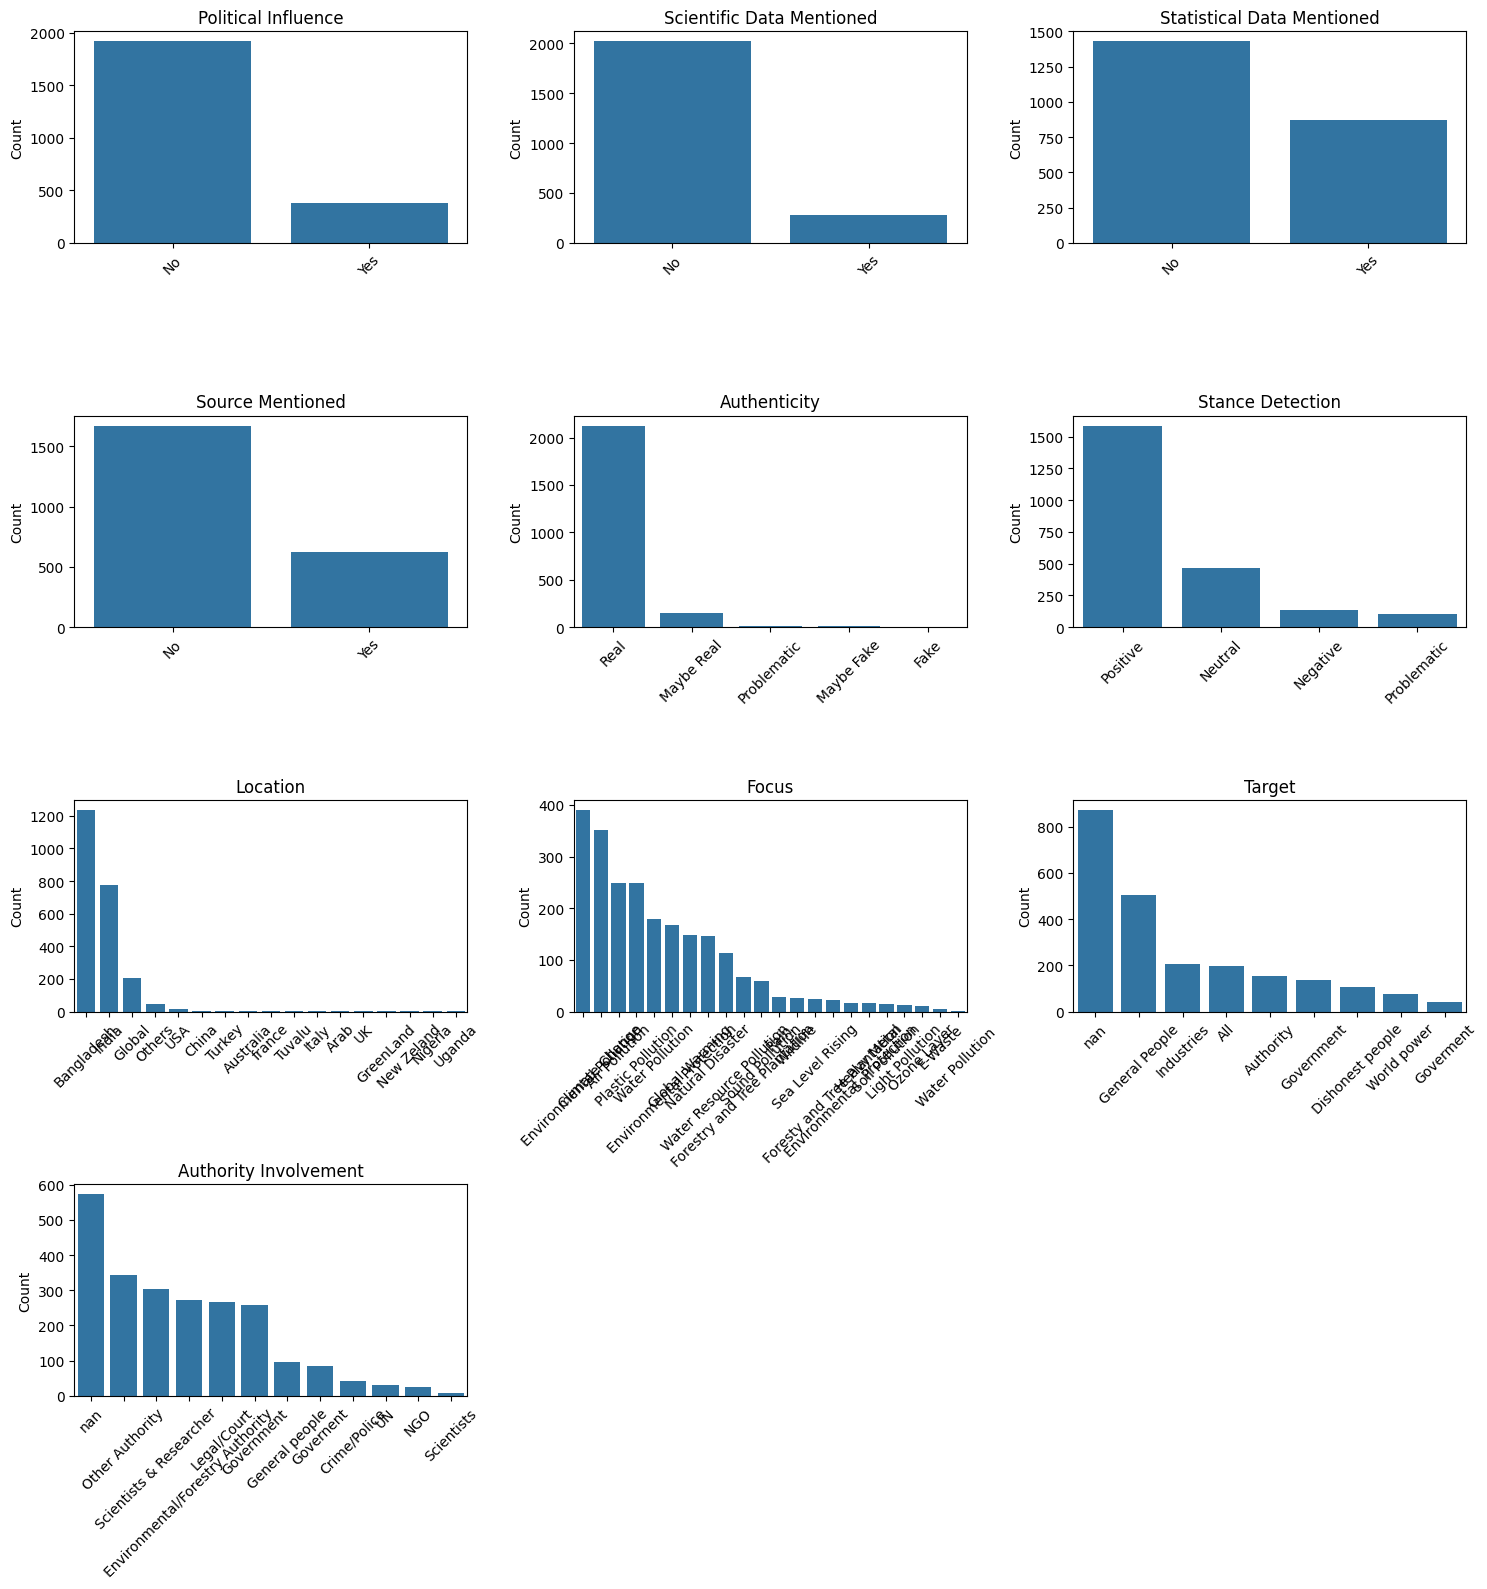

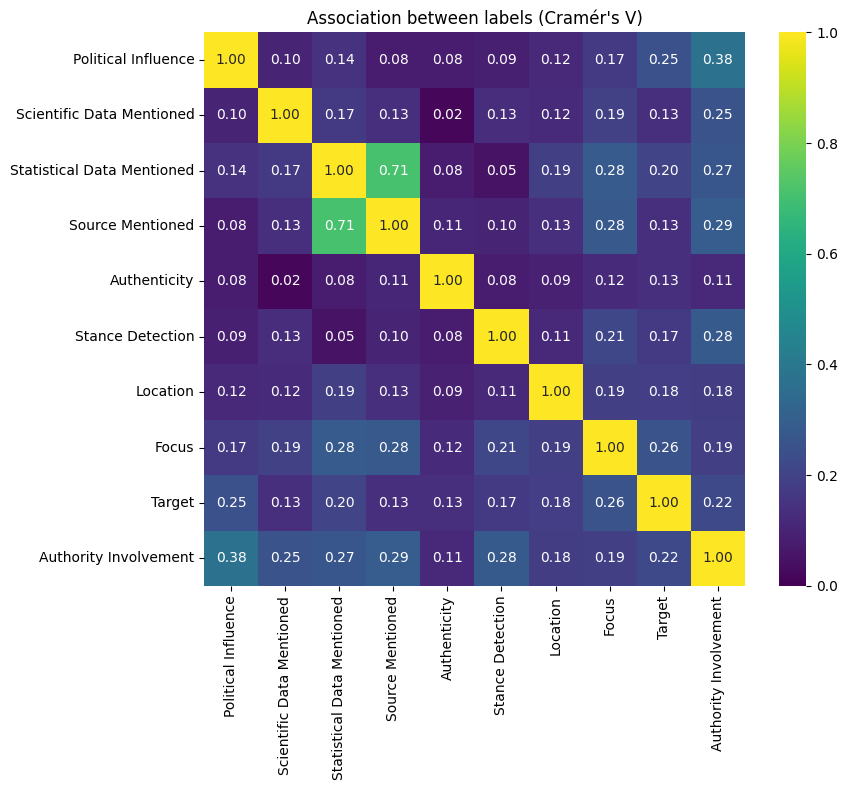

In [2]:
"""
Visualize the Dhoroni dataset (ciol-research/Dhoroni on Hugging Face).
pip install pandas matplotlib seaborn huggingface_hub
"""
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from huggingface_hub import hf_hub_download

# ---- Load ----
path = hf_hub_download("ciol-research/Dhoroni", "dataset.csv", repo_type="dataset")
df = pd.read_csv(path)

print("Shape:", df.shape)
print("\nColumns:\n", df.dtypes)
print("\nMissing values:\n", df.isna().sum())
print("\nSample:\n", df.head())

# ---- Split columns ----
text_cols = [c for c in df.columns
             if df[c].dtype == object and df[c].astype(str).str.len().mean() > 50]
label_cols = [c for c in df.columns
              if c not in text_cols and df[c].nunique() <= 30]

# ---- 1. Label distributions (one subplot per annotation perspective) ----
n = len(label_cols)
if n:
    ncols = 3
    nrows = -(-n // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows))
    axes = axes.flatten() if n > 1 else [axes]
    for ax, col in zip(axes, label_cols):
        vc = df[col].astype(str).value_counts()
        sns.barplot(x=vc.index, y=vc.values, ax=ax)
        ax.set_title(col)
        ax.set_xlabel("")
        ax.set_ylabel("Count")
        ax.tick_params(axis="x", rotation=45)
    for ax in axes[n:]:
        ax.axis("off")
    plt.tight_layout()
    plt.savefig("label_distributions.png", dpi=150)
    plt.show()

# ---- 2. Text length distributions ----
for col in text_cols:
    words = df[col].astype(str).str.split().str.len()
    plt.figure(figsize=(7, 4))
    sns.histplot(words, bins=50, kde=True)
    plt.title(f"Word count: {col}")
    plt.xlabel("Words")
    plt.tight_layout()
    plt.savefig(f"length_{col}.png", dpi=150)
    plt.show()

# ---- 3. Correlation between label columns (Cramér's V) ----
def cramers_v(x, y):
    import numpy as np
    from scipy.stats import chi2_contingency
    ct = pd.crosstab(x, y)
    if min(ct.shape) < 2:
        return 0.0
    chi2 = chi2_contingency(ct)[0]
    n_ = ct.values.sum()
    return np.sqrt(chi2 / (n_ * (min(ct.shape) - 1)))

if len(label_cols) > 1:
    mat = pd.DataFrame(index=label_cols, columns=label_cols, dtype=float)
    for a in label_cols:
        for b in label_cols:
            mat.loc[a, b] = cramers_v(df[a].astype(str), df[b].astype(str))
    plt.figure(figsize=(1 + 0.8 * len(label_cols), 0.8 * len(label_cols)))
    sns.heatmap(mat, annot=True, fmt=".2f", cmap="viridis", vmin=0, vmax=1)
    plt.title("Association between labels (Cramér's V)")
    plt.tight_layout()
    plt.savefig("label_association.png", dpi=150)
    plt.show()

In [3]:
# ===== Cell 1: Install =====
!pip install -q datasets scikit-learn

In [4]:
# ===== Cell 2: Imports =====
import os, zipfile, random
import pandas as pd
import torch
from tqdm.auto import tqdm
from time import time
from huggingface_hub import hf_hub_download
from transformers import AutoTokenizer, AutoModelForCausalLM, pipeline, logging
from sklearn.metrics import classification_report, confusion_matrix

In [5]:
# ===== Cell 3: Load Dhoroni (labels CSV + article text files) =====
REPO = "ciol-research/Dhoroni"

csv_path = hf_hub_download(REPO, "dataset.csv", repo_type="dataset")
zip_path = hf_hub_download(REPO, "dataset_files.zip", repo_type="dataset")

extract_dir = "/content/dhoroni_files"
with zipfile.ZipFile(zip_path) as z:
    z.extractall(extract_dir)

# Map "ID-1.txt" -> full path (works whatever the folder structure in the zip is)
file_map = {}
for root, _, files in os.walk(extract_dir):
    for f in files:
        if f.endswith(".txt"):
            file_map[f] = os.path.join(root, f)
print(f"Found {len(file_map)} article files")

meta = pd.read_csv(csv_path)
meta.columns = meta.columns.str.strip()
print(meta.columns.tolist())

def read_article(fname):
    path = file_map.get(str(fname).strip())
    if path is None:
        return None
    with open(path, encoding="utf-8", errors="ignore") as fh:
        return fh.read().strip()

meta["body"] = meta["File"].apply(read_article)
print("Articles missing text:", meta["body"].isna().sum())

dataset_files.zip: reconstructing file:   0%|          |  0.00B / 4.59MB            

dataset_files.zip: downloading bytes:           |  0.00B            

Found 2300 article files
['dates', 'Title', 'File', 'Political Influence', 'Scientific Data Mentioned', 'Statistical Data Mentioned', 'Source Mentioned', 'Authenticity', 'Stance Detection', 'Location', 'Focus', 'Target', 'Authority Involvement']
Articles missing text: 0


In [6]:
# ===== Cell 4: Build the classification DataFrame =====
class_labels = ["Positive", "Negative", "Neutral", "Problematic"]
MAX_CHARS = 1200

meta["Stance Detection"] = meta["Stance Detection"].astype(str).str.strip()
data = meta[meta["Stance Detection"].isin(class_labels)].copy()

data["text"] = data.apply(
    lambda r: f"{r['Title']}\n{(r['body'] or '')[:MAX_CHARS]}".strip(), axis=1
)
data["label"] = data["Stance Detection"]
print(data["label"].value_counts())

N = 100
parts = [g.sample(min(len(g), max(5, int(N * len(g) / len(data)))), random_state=42)
         for _, g in data.groupby("label")]
df = (pd.concat(parts).sample(frac=1, random_state=42)
        .reset_index(drop=True)[["text", "label"]])
print(df.shape)
print(df.head())

label
Positive       1586
Neutral         470
Negative        137
Problematic     107
Name: count, dtype: int64
(98, 2)
                                                text        label
0  কর্তব্যে অবিচল, পরিবেশ বাঁচাতে সাইকেল নিয়ে মণ্...     Positive
1  ফের দূষিত শহরের বাতাস\nবৃষ্টি থামতেই ফের ঊর্ধ্...     Positive
2  নদী-দূষণ রোধে গাফিলতি কবুল\nদূষণমাত্রা স্বাভাব...  Problematic
3  গঙ্গায় ভেসে উঠছে মরা মাছের ঝাঁক, ধরতে হুড়োহুড...      Neutral
4  ‘ভবিষ্যৎ প্রজন্মের জন্য বাসযোগ্য পরিবেশ তৈরিতে...     Positive


In [7]:
# ===== Cell 5: Zero-shot prompt =====
def build_prompt(text):
    instruction = (
        "You are a helpful assistant that classifies the stance of Bengali "
        "climate change and environmental news articles. "
        f"Choose one of the following categories: {', '.join(class_labels)}.\n"
        "Positive = supportive of environmental protection or reports progress/action; "
        "Negative = reports harm, failure or opposes protection efforts; "
        "Neutral = purely factual with no clear stance; "
        "Problematic = controversial, conflicting or misleading framing.\n"
        "Only respond with a single word—the correct category."
    )
    return f'{instruction}\n\nArticle: "{text}"\nStance:'

print(build_prompt(df["text"][0][:300]))

You are a helpful assistant that classifies the stance of Bengali climate change and environmental news articles. Choose one of the following categories: Positive, Negative, Neutral, Problematic.
Positive = supportive of environmental protection or reports progress/action; Negative = reports harm, failure or opposes protection efforts; Neutral = purely factual with no clear stance; Problematic = controversial, conflicting or misleading framing.
Only respond with a single word—the correct category.

Article: "কর্তব্যে অবিচল, পরিবেশ বাঁচাতে সাইকেল নিয়ে মণ্ডপে মণ্ডপে ঘুরলেন শিলিগুড়ির পুলিশকর্তা
পুজোয় ‘ডিউটি’ করতে গিয়ে পরিবেশরক্ষার বার্তা দিতে অভিনব রাস্তা অবলম্বন করলেন শিলিগুড়ি পুলিশ কমিশনারেটের অ্যাসিস্ট্যান্ট কমিশনার শেখ আজাদ হোসেন। মণ্ডপে মণ্ডপে ব্যাটারিচালিত সাইকেল নিয়ে ঘুরলেন তিনি। তাতে পরিবেশরক্ষাও"
Stance:


In [8]:
# ===== Cell 6: Load model =====
model_name = "Qwen/Qwen2.5-3B-Instruct"   # Bangla-capable; swap to "microsoft/phi-2" to compare
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForCausalLM.from_pretrained(
    model_name,
    dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
    device_map="auto",
)

config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/35.6k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

In [9]:
# ===== Cell 7: Run inference (zero-shot) =====
pipe = pipeline("text-generation", model=model, tokenizer=tokenizer)
logging.set_verbosity_error()

def parse_label(output):
    out = output.strip().lower()
    for lab in class_labels:
        if out.startswith(lab.lower()):
            return lab
    for lab in class_labels:
        if lab.lower() in out:
            return lab
    return "Unknown"

predictions, raw_outputs = [], []
start_time = time()
for text in tqdm(df["text"], desc="Classifying zero-shot"):
    gen = pipe(build_prompt(text), max_new_tokens=5, do_sample=False,
               return_full_text=False)[0]["generated_text"]
    raw_outputs.append(gen)
    predictions.append(parse_label(gen))
end_time = time()
print(f"\n Inference time: {end_time - start_time:.2f} seconds")

Classifying zero-shot:   0%|          | 0/98 [00:00<?, ?it/s]


 Inference time: 96.14 seconds


In [10]:
# ===== Cell 8: Evaluate (zero-shot) =====
df["zero_shot_prediction"] = predictions

def evaluate_predictions(df, label_col="label",
                         pred_col="zero_shot_prediction", num_examples=5):
    df[label_col] = df[label_col].str.lower().str.strip()
    df[pred_col] = df[pred_col].str.lower().str.strip()

    correct = (df[label_col] == df[pred_col]).sum()
    total = len(df)
    print(f"Accuracy: {correct / total * 100:.2f}% ({correct}/{total} correct)\n")

    labels = [l.lower() for l in class_labels]
    print(classification_report(df[label_col], df[pred_col],
                                labels=labels, zero_division=0))
    print("Confusion matrix (rows=true, cols=pred):", labels)
    print(confusion_matrix(df[label_col], df[pred_col], labels=labels))

    mismatches = df[df[label_col] != df[pred_col]]
    if mismatches.empty:
        print("No mismatches found!")
        return
    print(f"\nShowing {min(num_examples, len(mismatches))} random mismatches:")
    for _, row in mismatches.sample(n=min(num_examples, len(mismatches)),
                                    random_state=42).iterrows():
        print(f"\nArticle: {row['text'][:300]}...")
        print(f"True label: {row[label_col]}")
        print(f"Predicted: {row[pred_col]}")

evaluate_predictions(df)

Accuracy: 35.71% (35/98 correct)

              precision    recall  f1-score   support

    positive       0.79      0.40      0.53        68
    negative       0.11      0.60      0.19         5
     neutral       0.17      0.15      0.16        20
 problematic       0.11      0.40      0.17         5

   micro avg       0.36      0.36      0.36        98
   macro avg       0.30      0.39      0.26        98
weighted avg       0.60      0.36      0.42        98

Confusion matrix (rows=true, cols=pred): ['positive', 'negative', 'neutral', 'problematic']
[[27 17 13 10]
 [ 0  3  1  1]
 [ 5  7  3  5]
 [ 2  0  1  2]]

Showing 5 random mismatches:

Article: ফের দূষণ শীর্ষে উঠে এল শিলিগুড়ি
ফের দূষণ শীর্ষে শিলিগুড়ি। মঙ্গলবার শিলিগুড়ির বাতাসের দূষণ পিছনে ফেলে দিয়েছে দেশের বাকি ৫৫টি শহরকে। জাতীয় দূষণ নিয়ন্ত্রণ পর্ষদের প্রকাশিত মঙ্গলবারের দূষণ তালিকায় শিলিগুড়ির দূষণ সূচক ছিল ৩৫৯। এ দিনের নিরিখে শিলিগুড়ির পরেই দেশের দ্বিতীয় দূষিত শহর আসানসোল। তৃতীয় আমদা...
True label: neutral
Predicted: neg